# 01. 탐색적 데이터 분석 (EDA) — 권순우

학습 이미지와 정답 JSON의 클래스 분포, 박스 크기, 라벨 누락 의심 항목 및 파일 상태를 분석합니다.

저장소 루트에서 실행하며, 데이터는 `data/raw/train_annotations`와 `data/raw/train_images`에 준비합니다.

In [1]:
from pathlib import Path
import os
import hashlib
from collections import Counter, defaultdict
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from src.dataset import load_records, build_class_map
from src.eda import (records_to_frames, dataset_summary, class_distribution,
                     image_size_stats, objects_per_image, bbox_stats, find_label_issues)
from src.visualize import set_korean_font

set_korean_font()
pd.set_option("display.max_colwidth", 90)
# 기본 경로는 팀 README 기준. 개인 검토 시에만 환경변수로 경로를 바꿀 수 있습니다.
RAW = Path(os.environ.get("PILL_EDA_RAW_DIR", "data/raw"))
ANN_DIR = RAW / "train_annotations"
IMG_DIR = RAW / "train_images"
assert ANN_DIR.is_dir() and IMG_DIR.is_dir(), "README대로 data/raw/에 데이터를 준비해주세요."


## 1. 데이터 읽기
사진 한 장에 여러 알약이 있으므로 사진 수와 정답 상자 수를 나눠 봅니다.

In [2]:
records, categories = load_records(ANN_DIR)
class_map = build_class_map(records, categories)
images_df, boxes_df = records_to_frames(records, class_map)
display(dataset_summary(images_df, boxes_df).to_frame("값"))


,값
이미지 수,232.00
박스 수,763.00
클래스 수,56.00
이미지당 평균 알약 수,3.29
클래스당 박스 수 (최소),3.00
클래스당 박스 수 (중앙값),9.00
클래스당 박스 수 (최대),153.00
이미지 크기 종류,1.00


**확인한 내용:** 학습 사진 232장, 알약 56종, 정답 상자 763개입니다. 사진 수보다 상자가 많은 이유는 한 사진에 알약이 여러 개 있기 때문입니다.


## 2. 클래스 분포
어떤 종류는 많이 보고, 어떤 종류는 적게 보는지 확인합니다.

최대 153개 / 최소 3개 = 51배


,category_id,name,n_boxes,n_images,share_%
0,3351,일양하이트린정 2mg,153,153,20.05
1,3483,기넥신에프정(은행엽엑스)(수출용),45,45,5.90
2,35206,아토젯정 10/40mg,37,37,4.85
3,16262,크레스토정 20mg,23,23,3.01
4,21325,아토르바정 10mg,22,22,2.88
5,16232,리피토정 20mg,21,21,2.75
6,20238,플라빅스정 75mg,20,20,2.62
7,3832,뉴로메드정(옥시라세탐),20,20,2.62
8,36637,로수젯정10/5밀리그램,19,19,2.49
9,29667,리바로정 4mg,18,18,2.36


,category_id,name,n_boxes,n_images,share_%
46,12247,아빌리파이정 10mg,3,3,0.39
47,29451,레일라정,3,3,0.39
48,27993,졸로푸트정 100mg,3,3,0.39
49,27926,울트라셋이알서방정,3,3,0.39
50,24850,놀텍정 10mg,3,3,0.39
51,22362,맥시부펜이알정 300mg,3,3,0.39
52,13395,써스펜8시간이알서방정 650mg,3,3,0.39
53,16551,동아가바펜틴정 800mg,3,3,0.39
54,19552,트루비타정 60mg/병,3,3,0.39
55,21771,라비에트정 20mg,3,3,0.39


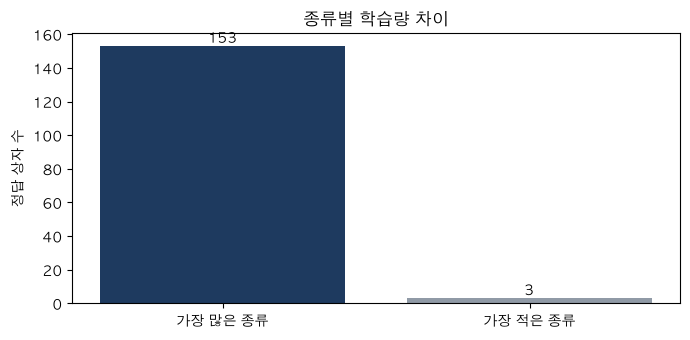

In [3]:
class_df = class_distribution(boxes_df)
display(class_df.head(10))
display(class_df.tail(10))
most, least = int(class_df.n_boxes.max()), int(class_df.n_boxes.min())
print(f"최대 {most}개 / 최소 {least}개 = {most / least:.0f}배")
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(["가장 많은 종류", "가장 적은 종류"], [most, least], color=["#1E3A5F", "#909AA6"])
ax.set_ylabel("정답 상자 수")
ax.set_title("종류별 학습량 차이")
for i, value in enumerate([most, least]):
    ax.text(i, value + 2, str(value), ha="center")
fig.tight_layout()
plt.show()


가장 많은 클래스는 153개, 가장 적은 클래스는 3개로 51배 차이입니다. 클래스 불균형이 있으므로 전체 성능과 클래스별 성능을 함께 확인할 필요가 있습니다.

## 3. 이미지 크기와 이미지당 알약 수

In [4]:
display(image_size_stats(images_df))
display(objects_per_image(images_df))
print("이미지당 알약 수를 합산한 박스 수:", int(images_df.n_objects.sum()))


이미지당 알약 수를 합산한 박스 수: 763


,width,height,n_images
0,976,1280,232


,n_objects,n_images
0,2,7
1,3,151
2,4,74


이미지 크기는 JSON 기준 모두 976×1280입니다. 알약이 2개인 사진 7장, 3개인 사진 151장, 4개인 사진 74장으로 총 232장입니다. 알약 수의 가중합은 정답 박스 수 763개와 일치합니다.

## 4. 박스 크기·비율
사진을 줄일 때 알약의 세부 정보가 얼마나 작아질지 살펴봅니다.

In [5]:
display(bbox_stats(boxes_df))
class_size = (boxes_df.groupby(["category_id", "name"])
              .agg(n_boxes=("name", "size"), mean_rel_area=("rel_area", "mean"))
              .sort_values("mean_rel_area").reset_index())
display(class_size.head(10))


,count,mean,std,min,5%,25%,50%,75%,95%,max
box_w,763.0,250.008,73.772,125.000,180.000,189.500,230.000,285.000,408.800,529.000
box_h,763.0,265.764,95.653,126.000,181.000,191.000,227.000,316.000,451.000,664.000
area,763.0,70384.793,42608.637,23250.000,33485.300,36672.000,53600.000,93492.500,155420.800,272435.000
aspect,763.0,0.992,0.269,0.396,0.589,0.829,1.000,1.041,1.543,2.108
rel_area,763.0,0.056,0.034,0.019,0.027,0.029,0.043,0.075,0.124,0.218


,category_id,name,n_boxes,mean_rel_area
0,19607,스토가정 10mg,6,0.019586
1,1900,보령부스파정 5mg,15,0.023243
2,12247,아빌리파이정 10mg,3,0.026837
3,3351,일양하이트린정 2mg,153,0.027963
4,27777,카나브정 60mg,3,0.028295
5,22074,리피로우정 20mg,16,0.028404
6,21771,라비에트정 20mg,3,0.028540
7,16232,리피토정 20mg,21,0.029272
8,19861,노바스크정 5mg,6,0.030665
9,21325,아토르바정 10mg,22,0.031204


박스 면적 평균이 작은 10개 클래스는 이미지 면적의 약 2.0~3.1%를 차지합니다. 입력 해상도에 따른 작은 객체의 검출 성능 비교가 필요합니다. 박스 면적은 알약 자체의 면적이나 각인 글자 크기와 다릅니다.

## 5. 라벨 오류 의심 항목
자동 검사 결과는 삭제 목록이 아니라 사람이 다시 볼 후보입니다.

In [6]:
issues = find_label_issues(images_df, boxes_df, image_dir=IMG_DIR)
display(issues["issue"].value_counts().to_frame("의심 항목 수"))
display(issues)


,의심 항목 수
issue,
heavy_overlap,3
out_of_bounds,1


,file_name,issue,category_id
0,K-003351-016262-018357_0_2_0_2_75_000_200.png,out_of_bounds,18357.0
1,K-001900-016548-019607-033009_0_2_0_2_70_000_200.png,heavy_overlap,NaN
2,K-003351-020238-031863_0_2_0_2_70_000_200.png,heavy_overlap,NaN
3,K-003351-029667-031863_0_2_0_2_70_000_200.png,heavy_overlap,NaN


**발견:** `out_of_bounds` 1건, `heavy_overlap` 3건입니다. 실제 알약이 겹쳐 있을 수도 있어 자동 검사만으로 정답을 삭제하면 안 됩니다.


## 6. 추가 점검: 파일명 조합과 알약별 정답 JSON 비교

사진 이름의 `K-001900-...` 부분에서 예상 알약 코드를 읽고, 해당 조합 폴더 안에 알약별 정답 JSON이 있는지 확인합니다.

**전제:** 파일명이 실제 촬영 알약 조합을 정확히 나타낸다는 가정입니다. 결과는 파일명 기준 누락 의심이며 시각 확인 전 확정 오류가 아닙니다.


In [7]:
missing_rows = []
expected_count = 0
for image_path in sorted(IMG_DIR.glob("*.png")):
    combo = image_path.stem.split("_")[0]
    for pill_code in combo.split("-")[1:]:
        expected_count += 1
        expected = ANN_DIR / (combo + "_json") / ("K-" + pill_code) / (image_path.stem + ".json")
        if not expected.is_file():
            missing_rows.append({"image": image_path.name, "pill_code": "K-" + pill_code})
missing_df = pd.DataFrame(missing_rows, columns=["image", "pill_code"])
actual_json_count = len(list(ANN_DIR.rglob("*.json")))
print(f"파일명 기준 예상 JSON: {expected_count} / 실제 JSON: {actual_json_count}")
print(f"누락 의심: {len(missing_df)}개")
display(missing_df)


파일명 기준 예상 JSON: 771 / 실제 JSON: 763
누락 의심: 8개


,image,pill_code
0,K-003351-013900-021325_0_2_0_2_70_000_200.png,K-003351
1,K-003351-013900-036637_0_2_0_2_70_000_200.png,K-003351
2,K-003351-020014-022074_0_2_0_2_90_000_200.png,K-020014
3,K-003351-021325-032310_0_2_0_2_90_000_200.png,K-032310
4,K-003351-032310-038162_0_2_0_2_70_000_200.png,K-003351
5,K-003351-033880-038162_0_2_0_2_75_000_200.png,K-033880
6,K-003351-035206-041768_0_2_0_2_70_000_200.png,K-003351
7,K-003544-004543-012247-016548_0_2_0_2_90_000_200.png,K-004543


파일명 기준 예상 정답 JSON은 771개, 실제 파일은 763개로 차이는 8개입니다. 아래에서 해당 사진을 정답 박스와 대조한 결과를 정리합니다.

### 사진 대조 결과

위 목록의 8장을 원본 정답 박스와 겹쳐 직접 확인했습니다. 1~7번 사진에는 알약 3개와 박스 2개, 8번 사진에는 알약 4개와 박스 3개가 있었습니다. 각 사진에서 실제로 보이는 알약 1개에 박스가 없어 총 8개 박스 누락을 확인했습니다.

아래 `visible_pills`와 `unboxed_position`은 사진을 직접 보고 기록한 관찰값입니다. `existing_boxes`는 정답 파일에서 읽은 값입니다. 이미지별 JSON은 전체 학습 정답 폴더에서도 다시 검색했습니다.

박스가 없는 객체의 존재를 확인한 것이며, 누락 클래스 코드는 파일명에서 추정한 값입니다. 약품 종류 자체를 사진만으로 확정하지 않았습니다. 기존 자동 검사에서 나온 박스 의심 항목 4건과는 별도 결과입니다.


In [8]:
# 사진을 직접 보고 기록한 관찰값
visual_observations = [{'image': 'K-003351-013900-021325_0_2_0_2_70_000_200.png', 'visible_pills': 3, 'unboxed_position': '아래쪽 주황색 원형'}, {'image': 'K-003351-013900-036637_0_2_0_2_70_000_200.png', 'visible_pills': 3, 'unboxed_position': '아래쪽 주황색 원형'}, {'image': 'K-003351-020014-022074_0_2_0_2_90_000_200.png', 'visible_pills': 3, 'unboxed_position': '왼쪽 아래 분홍색 원형'}, {'image': 'K-003351-021325-032310_0_2_0_2_90_000_200.png', 'visible_pills': 3, 'unboxed_position': '오른쪽 아래 노란색 타원형'}, {'image': 'K-003351-032310-038162_0_2_0_2_70_000_200.png', 'visible_pills': 3, 'unboxed_position': '아래쪽 주황색 원형'}, {'image': 'K-003351-033880-038162_0_2_0_2_75_000_200.png', 'visible_pills': 3, 'unboxed_position': '왼쪽 아래 노란색 타원형'}, {'image': 'K-003351-035206-041768_0_2_0_2_70_000_200.png', 'visible_pills': 3, 'unboxed_position': '아래쪽 주황색 원형'}, {'image': 'K-003544-004543-012247-016548_0_2_0_2_90_000_200.png', 'visible_pills': 4, 'unboxed_position': '오른쪽 위 흰색 원형'}]
review_df = pd.DataFrame(visual_observations)
boxes_by_image = {r["file_name"]: len(r["boxes"]) for r in records}
review_df["existing_boxes"] = review_df["image"].map(boxes_by_image)
review_df["unboxed_pills"] = review_df["visible_pills"] - review_df["existing_boxes"]
review_df["json_files_found"] = review_df["image"].map(
    lambda name: len(list(ANN_DIR.rglob(Path(name).with_suffix(".json").name))))
assert set(review_df.image) == set(missing_df.image)
assert (review_df.unboxed_pills == 1).all()
assert (review_df.json_files_found == review_df.existing_boxes).all()
display(review_df)
print("사진 대조" + "로 확인한 박스 누락:", int(review_df.unboxed_pills.sum()), "개")


사진 대조로 확인한 박스 누락: 8 개


,image,visible_pills,unboxed_position,existing_boxes,unboxed_pills,json_files_found
0,K-003351-013900-021325_0_2_0_2_70_000_200.png,3,아래쪽 주황색 원형,2,1,2
1,K-003351-013900-036637_0_2_0_2_70_000_200.png,3,아래쪽 주황색 원형,2,1,2
2,K-003351-020014-022074_0_2_0_2_90_000_200.png,3,왼쪽 아래 분홍색 원형,2,1,2
3,K-003351-021325-032310_0_2_0_2_90_000_200.png,3,오른쪽 아래 노란색 타원형,2,1,2
4,K-003351-032310-038162_0_2_0_2_70_000_200.png,3,아래쪽 주황색 원형,2,1,2
5,K-003351-033880-038162_0_2_0_2_75_000_200.png,3,왼쪽 아래 노란색 타원형,2,1,2
6,K-003351-035206-041768_0_2_0_2_70_000_200.png,3,아래쪽 주황색 원형,2,1,2
7,K-003544-004543-012247-016548_0_2_0_2_90_000_200.png,4,오른쪽 위 흰색 원형,3,1,3


## 7. 실제 이미지 파일 검사
사진이 열리는지, 실제 픽셀 크기가 JSON과 일치하는지, 완전히 같은 파일이 있는지 확인합니다.

In [9]:
sizes = Counter()
file_hashes = defaultdict(list)
unreadable = []
size_mismatches = []
record_by_name = {record["file_name"]: record for record in records}
for image_path in sorted(IMG_DIR.glob("*.png")):
    try:
        with Image.open(image_path) as image:
            size = image.size
            image.verify()
        sizes[size] += 1
        record = record_by_name.get(image_path.name)
        if record is not None and size != (record["width"], record["height"]):
            size_mismatches.append(image_path.name)
        file_hashes[hashlib.sha256(image_path.read_bytes()).hexdigest()].append(image_path.name)
    except Exception as exc:
        unreadable.append({"file_name": image_path.name, "error": type(exc).__name__})
duplicate_groups = [names for names in file_hashes.values() if len(names) > 1]
print("실제 사진 크기별 수:", dict(sizes))
print("읽기/검증 실패:", len(unreadable))
print("JSON 크기와 불일치:", len(size_mismatches))
print("완전히 같은 파일의 중복 그룹:", len(duplicate_groups))


실제 사진 크기별 수: {(976, 1280): 232}
읽기/검증 실패: 0
JSON 크기와 불일치: 0
완전히 같은 파일의 중복 그룹: 0


**발견:** 232장 모두 정상 검증됐고 실제 크기도 모두 976×1280입니다. 크기 불일치와 완전히 같은 파일 중복은 발견되지 않았습니다.

**한계:** SHA256 검사는 바이트가 같은 파일만 찾습니다. 같은 알약 조합을 비슷한 각도에서 찍은 사진까지 걸러주는 검사는 아닙니다.


## 8. 결론

- 학습 이미지 232장, 클래스 56개, 정답 박스 763개를 확인했습니다.
- 클래스별 박스 수는 최소 3개, 최대 153개로 불균형이 있습니다.
- 파일명 기준 누락 의심 8장을 사진과 대조해, 각 사진에 실제로 보이는 알약 1개씩 총 8개의 정답 박스가 없음을 확인했습니다. 누락 클래스 코드는 파일명 기준 추정입니다.
- 자동 검사에서 나온 범위 초과 1건·큰 겹침 3건은 추가 검토 후보입니다.
- 이미지 232장은 모두 정상이며, 메타데이터 크기 불일치와 바이트 단위 중복은 발견되지 않았습니다.
- 누락 라벨의 처리 기준을 합의하고 클래스별·작은 객체 검출 성능을 확인할 필요가 있습니다.
